# HPCQC Hands-on
## CPU, GPU and QPU backends with CUDA-Q

This notebook shows **how hybrid classical-quantum exeuction and dataflow works between classical CPU, GPU, and QPU with CUDA-Q** on the LRZ HPCQC system. It is an infrastructure demo, not a quantum algorithm. The circuit is simply GHZ.

```
  host (CPU)                quantum backends
 ┌──────────────┐  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ CPU backend              │  Case 1
 │              │ ◀─────── │ qpp-cpu (cudaq-sim)      │
 │              │  counts  └──────────────────────────┘
 │              │
 │              │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ GPU backend              │  Case 2
 │              │ ◀─────── │ nvidia (cudaq-sim)       │
 │              │  counts  └──────────────────────────┘
 │ list[float]  │
 │ counts       │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ multi-GPU backend        │  Case 3
 │              │ ◀─────── │ nvidia, mqpu (cudaq-sim) │
 │              │  counts  └──────────────────────────┘
 │              │
 │              │  sample  ┌──────────────────────────┐
 │              │ ───────▶ │ IQM QPU backend          │  Case 4
 │              │ ◀─────── │ iqm (LRZ HPC-QC)         │
 └──────────────┘  counts  └──────────────────────────┘
```

The host (CPU) always holds the parameters and the results. The four cases differ only in where the kernel runs, selected with `cudaq.set_target(...)`. Each run is timed.

**Run on BEAST via the portal:** use the `cudaq-gpu-env` kernel on a compute node. Case 3 needs two or more GPUs. Case 4 needs the `iqm_eqe1` license and an IQM token.

## Setup

In [1]:
import os
import time

import numpy as np
import cudaq
import matplotlib.pyplot as plt

SHOTS = 1000
SCALING_QUBITS = [10, 15, 20]     # circuit sizes for the CPU vs GPU comparison
MULTI_GPU_CIRCUITS = 8            # circuits in the case 3 batch

USE_QPU = True                   # True only in a session with the iqm_eqe1 license
IQM_SERVER_URL = os.environ.get("IQM_SERVER_URL", "https://qan06.beast.lrz.de/station/")
IQM_TOKEN_FILE = os.path.expanduser("~/.iqmclient_eqe1_token")

OUTPUT_DIR = "./hpcqc-output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

N_GPUS = cudaq.num_available_gpus()
HAS_GPU_SIM = N_GPUS > 0 and cudaq.has_target("nvidia")
cudaq.set_random_seed(11)

COLORS = {"CPU": "#2a78d6", "GPU": "#eb6834", "multi-GPU": "#1baf7a", "QPU": "#eda100"}
MARKERS = {"CPU": "o", "GPU": "s", "multi-GPU": "^", "QPU": "D"}

print(f"{cudaq.__version__.split('(')[0].strip()}  |  GPUs visible: {N_GPUS}")

CUDA-Q Version 0.14.2  |  GPUs visible: 1


## Kernels and helpers

`GHZ` is the demo kernel. It allocates a `cudaq.qvector` of `n` qubits, applies `h` to the first qubit to create a superposition, and then a chain of `cx` gates (`x.ctrl` in CUDA-Q) entangles each qubit with the next. 

The ideal state is $(|0\dots0\rangle + |1\dots1\rangle)/\sqrt{2}$, so `cudaq.sample` should return only the all-zeros and all-ones bitstrings, each about 50% of the time. That gives a simple correctness check for every backend.


In [2]:
@cudaq.kernel
def ghz_state(qubit_count: int):
    q = cudaq.qvector(qubit_count)
    h(q[0])
    for i in range(1, qubit_count):
        cx(q[0], q[i])

def sample_ghz_state(qubit_count: int, shots_count: int):
    cudaq.sample(ghz_state, qubit_count, shots_count=10)          # warm-up (compilation)
    t0 = time.perf_counter()
    result = cudaq.sample(ghz_state, qubit_count, shots_count=shots_count)
    t1 = time.perf_counter()
    seconds = t1 - t0
    return result, seconds

print(cudaq.draw(ghz_state, 5))

def run_scaling():
    times = {}
    for n in SCALING_QUBITS:
        run = sample_ghz_state(n, SHOTS)
        times[n] = run[1]
        print(f"GHZ State{n:3d} qubits: {times[n] * 1e3:9.1f} ms per sample call")
    return times

ghz = {}        # backend -> (counts, seconds) for a small GHZ state
scaling = {}    # backend -> {qubits: seconds}

     ╭───╮                    
q0 : ┤ h ├──●────●────●────●──
     ╰───╯╭─┴─╮  │    │    │  
q1 : ─────┤ x ├──┼────┼────┼──
          ╰───╯╭─┴─╮  │    │  
q2 : ──────────┤ x ├──┼────┼──
               ╰───╯╭─┴─╮  │  
q3 : ───────────────┤ x ├──┼──
                    ╰───╯╭─┴─╮
q4 : ────────────────────┤ x ├
                         ╰───╯



## Case 1: CPU only

The kernel runs on the CPU state-vector simulator `qpp-cpu`. This is the baseline.

In [3]:
cudaq.set_target("qpp-cpu")
ghz["CPU"] = sample_ghz_state(5, SHOTS)     # (counts, seconds) for a 5-qubit GHZ state
print(ghz["CPU"][0])
scaling["CPU"] = run_scaling()

{ 00000:519 11111:481 }

GHZ State 10 qubits:      14.4 ms per sample call
GHZ State 15 qubits:      93.2 ms per sample call
GHZ State 20 qubits:    4280.9 ms per sample call


## Case 2: Single GPU

Same kernels, now on the GPU simulator `nvidia`. For one qubit, the GPU is no faster because launch overhead dominates. A simulator stores $2^n$ amplitudes, so the cost doubles with every qubit, and that is where the GPU pulls ahead.

In [4]:
if HAS_GPU_SIM:
    cudaq.set_target("nvidia")
    ghz["GPU"] = sample_ghz_state(5, SHOTS)
    print(ghz["GPU"][0])
    scaling["GPU"] = run_scaling()
else:
    print("No GPU simulator available: skipping case 2.")


{ 00000:490 11111:510 }

GHZ State 10 qubits:      12.7 ms per sample call
GHZ State 15 qubits:      13.7 ms per sample call
GHZ State 20 qubits:      15.0 ms per sample call


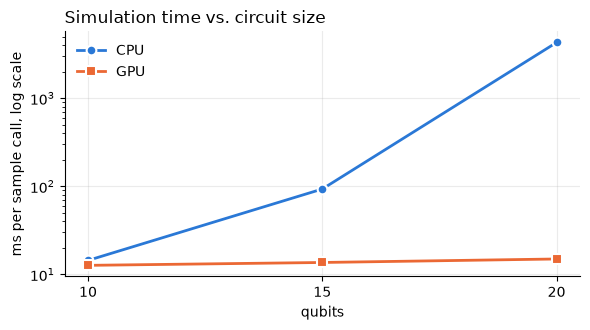

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.4))
for name, times in scaling.items():
    ax.plot(list(times), [t * 1e3 for t in times.values()], color=COLORS[name], lw=2,
            marker=MARKERS[name], ms=7, markeredgecolor="white", markeredgewidth=1.5, label=name)
ax.set_yscale("log")
ax.set_xticks(SCALING_QUBITS)
ax.set_xlabel("qubits")
ax.set_ylabel("ms per sample call, log scale")
ax.set_title("Simulation time vs. circuit size", loc="left")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/case2-cpu-vs-gpu.png", dpi=160, bbox_inches="tight")
plt.show()

## Case 3: Multi-GPU

With `option="mqpu"`, each GPU can act as a separate QPU. This needs more GPUs than this kernel has, so the `%%run_mgpu` cell magic from `lrzqc-client` submits a cell as a **separate Slurm job** to a compute node, which has 4 GPUs A100 for this case. The cell is not run direclty here: its code becomes a SLURM job, and submitted to the HPCQC cluster at LRZ.

- **Circuit batching:** `sample_async` sends each GHZ circuit to one GPU (`qpu_id`), and the circuits run in parallel.
- **Hamiltonian batching with MPI:** 4 MPI ranks, one GPU each. Every rank evaluates a quarter of the Hamiltonian's terms (`execution=cudaq.parallel.mpi`). To run the same code across nodes, only the first line changes: `%%run_mgpu ham_job --gpus 1 --nodes 2 --mpi`.

In [6]:
%load_ext lrzqc.hpc

In [7]:
%%run_mgpu batch_job --gpus 4
# Circuit batching: one process, each GPU is one simulated QPU
import time
import cudaq

@cudaq.kernel
def ghz_state(qubit_count: int):
    q = cudaq.qvector(qubit_count)
    h(q[0])
    for i in range(1, qubit_count):
        cx(q[0], q[i])

GHZ_QUBITS, N_CIRCUITS, SHOTS = 25, 16, 1000
cudaq.set_target("nvidia", option="mqpu")
n_qpus = cudaq.get_target().num_qpus()
print(f"GPUs in this job: {n_qpus}")

def run_batch(n):
    for i in range(n):                                            # warm-up on every GPU
        cudaq.sample_async(ghz_state, GHZ_QUBITS, shots_count=10, qpu_id=i).get()
    t0 = time.perf_counter()
    futures = [cudaq.sample_async(ghz_state, GHZ_QUBITS, shots_count=SHOTS, qpu_id=i % n)
               for i in range(N_CIRCUITS)]
    results = [f.get() for f in futures]
    return results, time.perf_counter() - t0

times = {}
for n in sorted({1, n_qpus}):
    results, times[n] = run_batch(n)
    print(f"{N_CIRCUITS} x {GHZ_QUBITS}-qubit GHZ on {n} GPU(s): {times[n]:.2f} s")
print(f"speedup: {times[1] / times[n_qpus]:.1f}x")
print(results[0])

batch_job = <MGPUJob 29380 4 GPU(s): QUEUED - waiting in the Slurm queue (Priority)>


In [8]:
%%run_mgpu ham_job --gpus 4 --mpi
# Hamiltonian batching: one MPI rank per GPU, the terms are split over the ranks
import socket, time
import cudaq
from cudaq import spin

cudaq.mpi.initialize()
rank, n_ranks = cudaq.mpi.rank(), cudaq.mpi.num_ranks()
cudaq.set_target("nvidia", option="mqpu")
print(f"rank {rank}/{n_ranks} on {socket.gethostname()}", flush=True)

@cudaq.kernel
def ghz_state(qubit_count: int):
    q = cudaq.qvector(qubit_count)
    h(q[0])
    for i in range(1, qubit_count):
        cx(q[0], q[i])

N_QUBITS, N_TERMS = 15, 100000
hamiltonian = cudaq.SpinOperator.random(N_QUBITS, N_TERMS, seed=13)   # same seed: same H on every rank
cudaq.observe(ghz_state, spin.z(0), N_QUBITS)                         # warm-up

if rank == 0:                                                         # baseline: one GPU
    t0 = time.perf_counter()
    e_1 = cudaq.observe(ghz_state, hamiltonian, N_QUBITS).expectation()
    t_1 = time.perf_counter() - t0

t0 = time.perf_counter()
e_n = cudaq.observe(ghz_state, hamiltonian, N_QUBITS,
                    execution=cudaq.parallel.mpi).expectation()      # terms split over all ranks
t_n = time.perf_counter() - t0

if rank == 0:
    print(f"{N_TERMS} terms on 1 GPU:          {t_1:.2f} s   <H> = {e_1:.6f}")
    print(f"{N_TERMS} terms on {n_ranks} GPUs (MPI): {t_n:.2f} s   <H> = {e_n:.6f}   speedup {t_1 / t_n:.1f}x")
cudaq.mpi.finalize()

ham_job = <MGPUJob 29383 4 GPU(s): QUEUED - waiting in the Slurm queue (Priority)>


#### Results - Case 3

Collect the two multi-GPU jobs submitted in Case 3. `result()` waits if a job is still queued or running, and prints each status change.

In [10]:
print(batch_job.result().output)
print(ham_job.result().output)

[16:12:00] job 29380: DONE - on wolpy08 in 0:00:35
# wolpy08, CUDA_VISIBLE_DEVICES=0,1,2,3
GPUs in this job: 4
16 x 25-qubit GHZ on 1 GPU(s): 0.29 s
16 x 25-qubit GHZ on 4 GPU(s): 0.23 s
speedup: 1.3x
{ 0000000000000000000000000:508 1111111111111111111111111:492 }


[16:12:00] job 29383: FAILED - ended without an exit code (time limit or cancelled)


JobFailedError: job 29383: ended without an exit code (time limit or cancelled)
# nodes: wolpy08, MPI ranks: 4 (1 GPU each), /home/di35hef/conda/x86_64/envs/cudaq-gpu-env/bin/mpirun
rank 1/4 on wolpy08
rank 0/4 on wolpy08
rank 2/4 on wolpy08
rank 3/4 on wolpy08
100000 terms on 1 GPU:          1.52 s   <H> = 0.000000
100000 terms on 4 GPUs (MPI): 1.09 s   <H> = 0.000000   speedup 1.4x

## Case 4: QPU

The same `GHZ` runs on the IQM QPU. Each `sample` call is one job, so the time is mostly network and queueing, not the quantum run itself. Results also show hardware noise.

The IQM target reads the token from `IQM_TOKEN`.

In [6]:
if USE_QPU:
    if not os.environ.get("IQM_TOKEN"):
        with open(IQM_TOKEN_FILE) as f:
            os.environ["IQM_TOKEN"] = f.read().strip()
    cudaq.set_target("iqm", url=IQM_SERVER_URL)
    ghz["QPU"] = sample_ghz_state(5, SHOTS)
    print(ghz["QPU"][0])
else:
    print("USE_QPU = False: skipping case 4.")


{ 00000:356 00001:50 00010:32 00011:4 00100:18 00101:4 00110:24 00111:5 01000:35 01001:13 01010:1 01011:2 01100:2 01101:1 01110:10 01111:21 10000:2 10001:7 10011:3 10100:1 10101:7 10110:9 10111:42 11000:1 11001:7 11010:7 11011:29 11100:1 11101:15 11110:35 11111:256 }



## Summary

The left plot shows that every backend returns the expected result, up to shot noise and, on the QPU, hardware noise. The right plot shows what the same sweep costs on each backend.

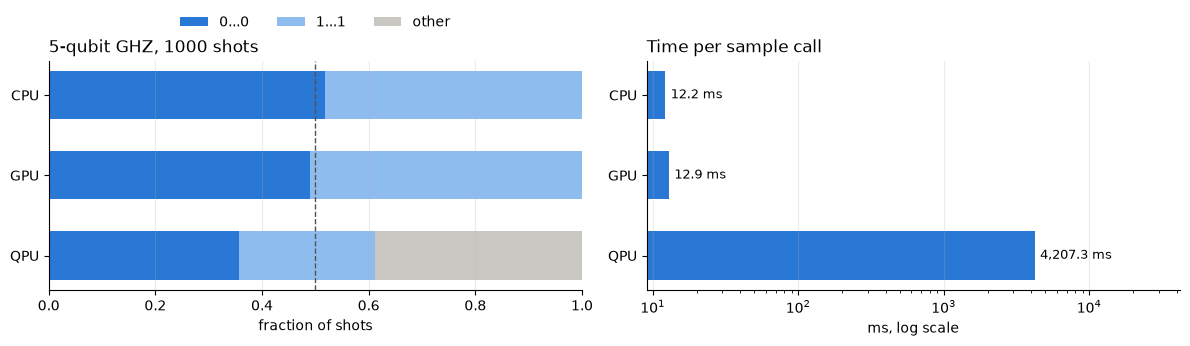

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))

names = list(ghz)
n_qubits = len(ghz[names[0]][0].most_probable())     # GHZ size, read from the bitstrings

# Left: where the shots landed. Ideal GHZ = 50% |0...0>, 50% |1...1>, 0% other
probs = []
for n in names:
    counts = ghz[n][0]
    zeros = counts.count("0" * n_qubits) / SHOTS
    ones = counts.count("1" * n_qubits) / SHOTS
    probs.append((zeros, ones, 1 - zeros - ones))
probs = np.array(probs)

left = np.zeros(len(names))
for col, (label, color) in enumerate([("0...0", "#2a78d6"), ("1...1", "#8fbcef"), ("other", "#c9c7c1")]):
    ax1.barh(names, probs[:, col], left=left, color=color, height=0.6, label=label)
    left += probs[:, col]
ax1.axvline(0.5, color="#52514e", lw=1, ls="--")
ax1.invert_yaxis()
ax1.set_xlim(0, 1)
ax1.set_xlabel("fraction of shots")
ax1.set_title(f"{n_qubits}-qubit GHZ, {SHOTS} shots", loc="left")
ax1.legend(frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.08))

# Right: time of one sample call per backend
ms = [ghz[n][1] * 1e3 for n in names]
ax2.barh(names, ms, color="#2a78d6", height=0.6)
for y, v in enumerate(ms):
    ax2.annotate(f"{v:,.1f} ms", (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax2.invert_yaxis()
ax2.set_xscale("log")
ax2.set_xlim(right=max(ms) * 10)    # room for the value labels
ax2.set_xlabel("ms, log scale")
ax2.set_title("Time per sample call", loc="left")

for ax in (ax1, ax2):
    ax.grid(alpha=0.25, axis="x")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/summary.png", dpi=160, bbox_inches="tight")
plt.show()


**Takeaways**

- The same kernel runs in all four cases. Only `cudaq.set_target` changes.
- **CPU:** fastest for small circuits.
- **GPU:** pays off as the qubit count grows.
- **Multi-GPU:** increases throughput when there are many circuits.
- **QPU:** time is mostly communication and queueing. That latency is what tighter GPU–QPU coupling such as NVQLink aims to reduce.